<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/10_2_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
%%bash
# OpenCV geliştirme paketlerini yükle
apt-get update -qq && apt-get install -y -qq libopencv-dev

cat << 'EOF' > custom_bm.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <limits>
#include <cmath>

cv::Mat computeDisparityBlockMatching(const cv::Mat& left,
                                      const cv::Mat& right,
                                      int numDisparities,
                                      int blockSize) {
    CV_Assert(left.type() == CV_8U && right.type() == CV_8U);
    CV_Assert(left.size() == right.size());
    CV_Assert(blockSize % 2 == 1 && blockSize >= 3);
    CV_Assert(numDisparities > 0);

    int rows = left.rows;
    int cols = left.cols;
    int r = blockSize / 2;

    // Çıktı: her piksel için float disparite değeri (geçersiz/sınır pikseller için 0)
    cv::Mat disp = cv::Mat::zeros(rows, cols, CV_32F);

    // Kenar payı bırakarak bloğun görüntü dışına taşmasını engelle
    // Sağ görüntüde (x - d - r) >= 0 olmalı -> x >= r + numDisparities - 1
    int startX = std::max(r, r + numDisparities - 1);
    int endX   = cols - r;
    int startY = r;
    int endY   = rows - r;

    for (int y = startY; y < endY; ++y) {
        const uchar* rowLeftBase = left.ptr<uchar>(y);
        for (int x = startX; x < endX; ++x) {
            int bestCost = std::numeric_limits<int>::max();
            int bestD = 0;

            for (int d = 0; d < numDisparities; ++d) {
                int rx = x - d;
                if (rx - r < 0) break;

                int sad = 0;
                for (int u = -r; u <= r; ++u) {
                    const uchar* pL = left.ptr<uchar>(y + u);
                    const uchar* pR = right.ptr<uchar>(y + u);
                    for (int v = -r; v <= r; ++v) {
                        sad += std::abs(static_cast<int>(pL[x + v]) -
                                      static_cast<int>(pR[rx + v]));
                    }
                }

                if (sad < bestCost) {
                    bestCost = sad;
                    bestD = d;
                }
            }

            disp.at<float>(y, x) = static_cast<float>(bestD);
        }
    }

    return disp;
}

int main() {
    cv::Mat imgLeft  = cv::imread("scene1.row3.col1.ppm", cv::IMREAD_GRAYSCALE);
    cv::Mat imgRight = cv::imread("scene1.row3.col3.ppm", cv::IMREAD_GRAYSCALE);

    if (imgLeft.empty() || imgRight.empty()) {
        std::cerr << "Goruntuler yuklenemedi!" << std::endl;
        return -1;
    }

    int numDisparities = 128; // 16 * 8
    int blockSize = 9;       // Tek sayı (5, 7, 9, 11...)

    cv::Mat dispFloat = computeDisparityBlockMatching(imgLeft, imgRight, numDisparities, blockSize);

    // Görselleştirme için 0-255 aralığına normalize et ve renklendir
    double minVal, maxVal;
    cv::minMaxLoc(dispFloat, &minVal, &maxVal);

    cv::Mat dispNorm, dispColor;
    double scale = (maxVal - minVal > 0.0) ? (255.0 / (maxVal - minVal)) : 1.0;
    dispFloat.convertTo(dispNorm, CV_8U, scale, -minVal * scale);

    cv::applyColorMap(dispNorm, dispColor, cv::COLORMAP_TURBO);
    cv::imwrite("disparity_custom_bm.png", dispColor);

    std::cout << "Tamamlandi: disparity_custom_bm.png olusturuldu." << std::endl;
    return 0;
}
EOF

g++ -O3 custom_bm.cpp -o custom_bm `pkg-config --cflags --libs opencv4`
./custom_bm

Tamamlandi: disparity_custom_bm.png olusturuldu.


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


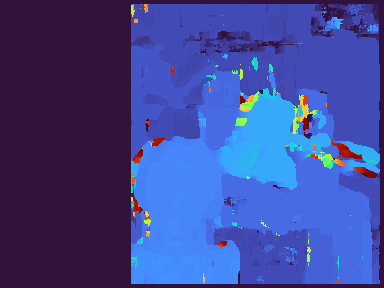

In [7]:
from IPython.display import Image, display

# Üretilen disparity görselini gösterelim
display(Image('disparity_custom_bm.png'))

In [6]:
!apt-get update -qq
!apt-get install -y -qq libopencv-dev pkg-config

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package pkg-config:amd64.
(Reading database ... 127046 files and directories currently installed.)
Preparing to unpack .../pkg-config_1.8.1-2build1_amd64.deb ...
Unpacking pkg-config:amd64 (1.8.1-2build1) ...
Setting up pkg-config:amd64 (1.8.1-2build1) ...
